## THE DATASET USED HERE COULD NOT PRODUCE A GOOD MODEL CHECK OUT THE OTHER ONE

# MY FIRST PROJECT (WITHOUT TUTORIAL)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('./student.csv')
df.head()

,StudentID,Name,Gender,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,ParentalSupport,FinalGrade,Study Hours,Attendance (%),Online Classes Taken
0,1.0,John,Male,85.0,15.0,78.0,1.0,High,80.0,4.8,59.0,False
1,2.0,Sarah,Female,90.0,20.0,85.0,2.0,Medium,87.0,2.2,70.0,True
2,3.0,Alex,Male,78.0,10.0,65.0,0.0,Low,68.0,4.6,92.0,False
3,4.0,Michael,Male,92.0,25.0,90.0,3.0,High,92.0,2.9,96.0,False
4,5.0,Emma,Female,NaN,18.0,82.0,2.0,Medium,85.0,4.1,97.0,True


In [3]:
df.shape

(1000, 12)

In [4]:
df = df.drop(['Name', 'Gender', 'ParentalSupport', 'Online Classes Taken'], axis=1)

In [5]:
df

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
0,1.0,85.0,15.0,78.0,1.0,80.0,4.8,59.0
1,2.0,90.0,20.0,85.0,2.0,87.0,2.2,70.0
2,3.0,78.0,10.0,65.0,0.0,68.0,4.6,92.0
3,4.0,92.0,25.0,90.0,3.0,92.0,2.9,96.0
4,5.0,NaN,18.0,82.0,2.0,85.0,4.1,97.0
...,...,...,...,...,...,...,...,...
995,NaN,85.0,20.0,NaN,1.0,72.0,0.8,80.0
996,4497.0,91.0,NaN,86.0,0.0,90.0,3.9,80.0
997,1886.0,85.0,8.0,82.0,2.0,68.0,0.4,54.0
998,7636.0,88.0,17.0,60.0,2.0,85.0,0.9,53.0


In [6]:
print(df.isnull().sum())

StudentID                    40
AttendanceRate               40
StudyHoursPerWeek            50
PreviousGrade                33
ExtracurricularActivities    43
FinalGrade                   40
Study Hours                  24
Attendance (%)               41
dtype: int64


In [7]:
print('OG Shape: ', df.shape)
print('Dropped Shape: ', df.dropna().shape)

OG Shape:  (1000, 8)
Dropped Shape:  (735, 8)


### REMOVE ROWS WITH 2 OR MORE NAN VALUES

In [8]:
df = df[df.isnull().sum(axis = 1) < 2].copy()

In [9]:
df.shape

(955, 8)

### FILL MISSING VALUES WITH THEIR MEDIANS

In [10]:
input_cols = [
    'StudyHoursPerWeek',
    'PreviousGrade',
    'StudentID', 'ExtracurricularActivities', 'Attendance (%)', 'AttendanceRate', 'Study Hours'
]

for col in input_cols:
    if df[col].dtype in ['int64', 'float64']:
        df[col] = df[col].fillna(df[col].median())

In [11]:
df

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
0,1.0,85.0,15.0,78.0,1.0,80.0,4.8,59.0
1,2.0,90.0,20.0,85.0,2.0,87.0,2.2,70.0
2,3.0,78.0,10.0,65.0,0.0,68.0,4.6,92.0
3,4.0,92.0,25.0,90.0,3.0,92.0,2.9,96.0
4,5.0,88.0,18.0,82.0,2.0,85.0,4.1,97.0
...,...,...,...,...,...,...,...,...
994,2787.0,78.0,20.0,60.0,0.0,62.0,1.6,70.0
996,4497.0,91.0,18.0,86.0,0.0,90.0,3.9,80.0
997,1886.0,85.0,8.0,82.0,2.0,68.0,0.4,54.0
998,7636.0,88.0,17.0,60.0,2.0,85.0,0.9,53.0


### DROP NAN VALUES IN FINAL GRADE COLUMN

In [12]:
df = df.dropna(subset=['FinalGrade'])

In [13]:
df

,StudentID,AttendanceRate,StudyHoursPerWeek,PreviousGrade,ExtracurricularActivities,FinalGrade,Study Hours,Attendance (%)
0,1.0,85.0,15.0,78.0,1.0,80.0,4.8,59.0
1,2.0,90.0,20.0,85.0,2.0,87.0,2.2,70.0
2,3.0,78.0,10.0,65.0,0.0,68.0,4.6,92.0
3,4.0,92.0,25.0,90.0,3.0,92.0,2.9,96.0
4,5.0,88.0,18.0,82.0,2.0,85.0,4.1,97.0
...,...,...,...,...,...,...,...,...
993,3592.0,90.0,25.0,60.0,1.0,87.0,1.7,79.0
994,2787.0,78.0,20.0,60.0,0.0,62.0,1.6,70.0
996,4497.0,91.0,18.0,86.0,0.0,90.0,3.9,80.0
997,1886.0,85.0,8.0,82.0,2.0,68.0,0.4,54.0


### SPLIT THE DATASET INTO X AND Y

In [15]:
X = df.drop(columns=['FinalGrade'])
y = df['FinalGrade']

In [16]:
print('X shape: ', X.shape)
print('y shape: ', y.shape)

print(X.head())
print(y.head())

X shape:  (929, 7)
y shape:  (929,)
   StudentID  AttendanceRate  StudyHoursPerWeek  PreviousGrade  \
0        1.0            85.0               15.0           78.0   
1        2.0            90.0               20.0           85.0   
2        3.0            78.0               10.0           65.0   
3        4.0            92.0               25.0           90.0   
4        5.0            88.0               18.0           82.0   

   ExtracurricularActivities  Study Hours  Attendance (%)  
0                        1.0          4.8            59.0  
1                        2.0          2.2            70.0  
2                        0.0          4.6            92.0  
3                        3.0          2.9            96.0  
4                        2.0          4.1            97.0  
0    80.0
1    87.0
2    68.0
3    92.0
4    85.0
Name: FinalGrade, dtype: float64


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0. ,-0.04, 0.01,...,-0.27, 0.35, 0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['StudentID','AttendanceRate','StudyHoursPerWeek',..., 'ExtracurricularActivities','Study Hours','Attendance (%)']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,78.28
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [19]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[80.12260657 80.38860483 79.21392428 79.85425978 79.67688696 80.58115587
 79.9568559  80.45893329 79.02556427 78.15640102]


In [20]:
comparison = pd.DataFrame({
    'Actual Grade': y_test,
    'Predicted Grade': y_pred
})

comparison.head(10)

,Actual Grade,Predicted Grade
815,80.0,80.122607
721,85.0,80.388605
35,87.0,79.213924
422,68.0,79.854260
210,80.0,79.676887
387,62.0,80.581156
116,72.0,79.956856
525,90.0,80.458933
514,80.0,79.025564
487,78.0,78.156401


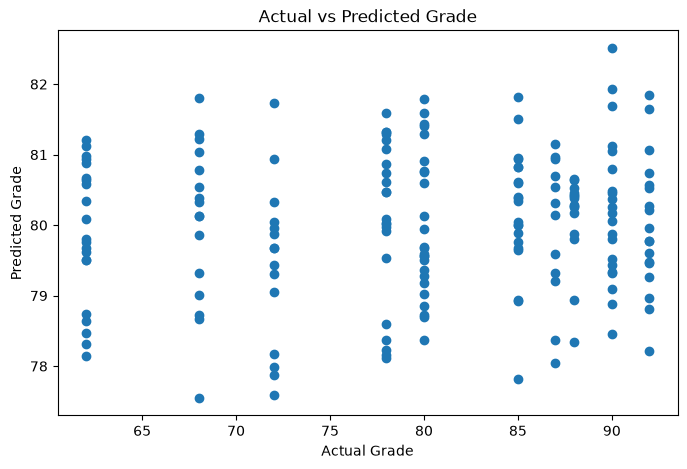

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Grade')
plt.ylabel('Predicted Grade')
plt.title('Actual vs Predicted Grade')

plt.show()

In [22]:
print(mean_absolute_error(y_test, y_pred),
mean_squared_error(y_test, y_pred),
r2_score(y_test, y_pred))

7.920945394387955 90.15115241010265 0.009034946158725687


In [23]:
df.corr(numeric_only=True)['FinalGrade'].sort_values(ascending=False)

FinalGrade                   1.000000
StudentID                    0.082527
Attendance (%)               0.043530
StudyHoursPerWeek            0.032637
Study Hours                  0.031024
PreviousGrade                0.004362
AttendanceRate              -0.010123
ExtracurricularActivities   -0.028141
Name: FinalGrade, dtype: float64

In [24]:
df['FinalGrade'].describe()

count    929.000000
mean      80.044133
std        9.478605
min       62.000000
25%       72.000000
50%       80.000000
75%       88.000000
max       92.000000
Name: FinalGrade, dtype: float64

In [25]:
df[['StudyHoursPerWeek', 'Study Hours']].corr()

,StudyHoursPerWeek,Study Hours
StudyHoursPerWeek,1.000000,-0.033485
Study Hours,-0.033485,1.000000


## DEFINE THE HYPER PARAMETERS TO TEST

In [26]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [27]:
rf = RandomForestRegressor(random_state=42)

In [28]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

In [ ]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


ValueError: 
All the 540 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
540 fits failed with the following error:
Traceback (most recent call last):
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/sklearn/ensemble/_forest.py", line 334, in fit
    X, y = validate_data(
           ^^^^^^^^^^^^^^
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py", line 3058, in validate_data
    X, y = check_X_y(X, y, **check_params)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py", line 1330, in check_X_y
    X = check_array(
        ^^^^^^^^^^^^
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py", line 1038, in check_array
    array = _asarray_with_order(array, order=order, dtype=dtype, xp=xp)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/sklearn/utils/_array_api.py", line 983, in _asarray_with_order
    array = numpy.asarray(array, order=order, dtype=dtype)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/xxavi/Documents/projects/students-score-pred/model/.venv/lib/python3.12/site-packages/pandas/core/generic.py", line 2027, in __array__
    arr = np.asarray(values, dtype=dtype)
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: could not convert string to float: 'female'


In [ ]:
-grid_search.best_score_

np.float64(8.19632285152177)

In [ ]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
test_r = r2_score(y_test, y_pred)

print(
    'Test MAE: ', test_mae,
    'Test R2: ', test_r
)

Test MAE:  7.955683491795515 Test R2:  -0.010579558214181883


In [ ]:
comparison = pd.DataFrame({
    'Actual Grade': y_test,
    'Predicted Grade': y_pred
})

comparison.head(10)

,Actual Grade,Predicted Grade
815,80.0,81.039683
721,85.0,81.121897
35,87.0,77.393845
422,68.0,80.242390
210,80.0,79.688020
387,62.0,79.629585
116,72.0,78.791990
525,90.0,81.122934
514,80.0,77.396718
487,78.0,78.852461


Text(0.5, 1.0, 'Actual vs Predicted Grade')

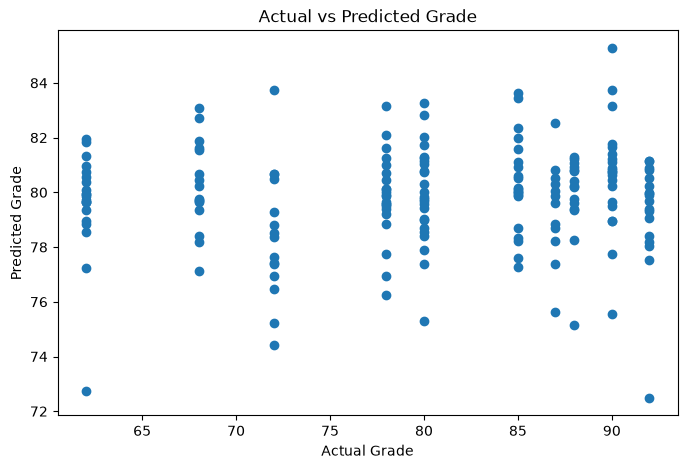

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Grade')
plt.ylabel('Predicted Grade')
plt.title('Actual vs Predicted Grade')